In [ ]:
!pip install gower scikit-bio

import pandas as pd
import numpy as np
import gower
from skbio.stats.ordination import pcoa
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
import seaborn as sns
import io

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 86.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 96.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-bio]


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving matrix E.csv to matrix E.csv
Saving matrix L.csv to matrix L.csv
Saving matrix Q.csv to matrix Q.csv


In [ ]:
def test_load_matrix_l():
    """Test loading and inspecting Matrix L (Abundance)."""
    print("\n================ TEST 1: MATRIX L ================")
    path_l = "matrix L.csv"
    try:
        matrix_l = pd.read_csv(path_l, index_col=0)
        print("Success! Matrix L loaded.")
        print(f"Shape (Locations × Species): {matrix_l.shape}")
        print("First 3 rows preview:")
        print(matrix_l.iloc[:3, :5]) # Print first 3 rows and first 5 species columns
        return matrix_l
    except Exception as e:
        print(f"ERROR loading Matrix L: {e}")
        return None

In [ ]:
def test_load_matrix_q():
    """Test loading, cleaning, and inspecting Matrix Q (Species Traits)."""
    print("\n================ TEST 2: MATRIX Q ================")
    path_q = "matrix Q.csv"
    try:
        matrix_q = pd.read_csv(path_q, index_col="Species")
        print("Success! Matrix Q loaded.")
        print(f"Shape (Species × Traits): {matrix_q.shape}")
        print(f"Columns found: {matrix_q.columns.tolist()}")

        # Test missing data handling for the 3 species
        cat_cols = ['Genus', 'Shape', 'Radiator', 'Colour']
        for col in cat_cols:
            if col in matrix_q.columns:
                matrix_q[col] = matrix_q[col].fillna('Unknown')

        num_cols = ['H', 'L', 'P', 'E']
        for col in num_cols:
            if col in matrix_q.columns:
                matrix_q[col] = pd.to_numeric(matrix_q[col], errors='coerce')
                matrix_q[col] = matrix_q[col].fillna(matrix_q[col].median())

        print("Missing data successfully handled ('Unknown' filled for categories, median for numbers).")
        print("First 3 rows preview:")
        print(matrix_q.iloc[:3])
        return matrix_q
    except Exception as e:
        print(f"ERROR loading Matrix Q: {e}")
        return None

In [ ]:
def test_load_matrix_e():
    """Test loading and parsing Matrix E (Abiotic Environment)."""
    print("\n================ TEST 3: MATRIX E ================")
    matrix_e_str = """Location,EL,LATITUDE,LONGITUDE,INDEX_UV,LX,T2M,T2MDEW,RH2M,Rd,Cd
L1,0.383606557,0.9,0.877737109,0.684340352,0.831600993,0.899941337,0.898848542,0.812002582,0.065410498,0.126896204
L2,0.403278689,0.784779983,0.879474418,0.710243876,0.840015426,0.861213144,0.89977246,0.872152364,0.060565276,0.209605338
L3,0.42295082,0.683205337,0.884271982,0.663171465,0.820268881,0.760760707,0.799670743,0.9,0.02422611,0.285119909
L4,0.118032787,0.737944739,0.877738572,0.818521702,0.844407936,0.883332694,0.9,0.836720875,0.041184388,0.08066973
L5,0.9,0.435752676,0.892444884,0.860421143,0.886335248,0.877293815,0.869520226,0.809154465,0.029071332,0.242688991
L6,0.427868852,0.426682128,0.890860622,0.706875806,0.811246833,0.9,0.878240828,0.785197649,0.060565276,0.660936615
L7,0.191803279,0.311518453,0.894623341,0.9,0.9,0.867735133,0.894158043,0.854262011,0.121130552,0.268917983
L8,0.47704918,0.317116644,0.898882675,0.809368285,0.852710126,0.883574249,0.874092192,0.803047826,0.036339166,0.522427142
L9,0.403278689,0.602725011,0.880180298,0.701847873,0.830883644,0.874809248,0.889289746,0.835336373,0.064199192,0.098911059
L10,0.870491803,0.699442854,0.9,0.695788569,0.8381374,0.8360569,0.871001881,0.873978793,0.060565276,0.186718701
L11,0.536065574,0.723159523,0.893251499,0.820584443,0.833527302,0.860350447,0.74425682,0.68080378,0.036339166,0.9
L12,0.526229508,0.344497586,0.894956739,0.850365277,0.691742958,0.860419462,0.881458137,0.848550944,0.9,0.01599589"""
    try:
        matrix_e = pd.read_csv(io.StringIO(matrix_e_str), index_col=0)
        print("Success! Matrix E loaded.")
        print(f"Shape (Locations × Environment Variables): {matrix_e.shape}")
        print("Variables found:", matrix_e.columns.tolist())
        print("First 3 rows preview:")
        print(matrix_e.iloc[:3, :4])
        return matrix_e
    except Exception as e:
        print(f"ERROR loading Matrix E: {e}")
        return None

if __name__ == "__main__":
    print("Starting step-by-step matrix verification...")
    l = test_load_matrix_l()
    q = test_load_matrix_q()
    e = test_load_matrix_e()
    print("\nVerification checks complete!")



Starting step-by-step matrix verification...

================ TEST 1: MATRIX L ================
Success! Matrix L loaded.
Shape (Locations × Species): (12, 35)
First 3 rows preview:
    S1  S2  S3  S4  S5
L1  20  19  19  14  15
L2  25  23  20  13  20
L3  37  30  26  11   4

================ TEST 2: MATRIX Q ================
Success! Matrix Q loaded.
Shape (Species × Traits): (35, 8)
Columns found: ['Genus', 'H', 'L', 'P', 'E', 'Shape', 'Radiator', 'Colour']
Missing data successfully handled ('Unknown' filled for categories, median for numbers).
First 3 rows preview:
        Genus  H    L     P      E    Shape Radiator Colour
Species                                                    
S1         M1  7  7.0  0.22  2.795  pinched    Shiny  black
S11        M1  7  7.0  0.22  2.795  pinched    Shiny  black
S2         M2  9  9.0  0.27  3.300  pinched    Hairy  black

================ TEST 3: MATRIX E ================
Success! Matrix E loaded.
Shape (Locations × Environment Variables): (12, 

In [ ]:
def load_and_clean_data():
    """Load matrices and preserve blank cells for Gower's native pairwise deletion."""
    print("Loading matrices...")

    # 1. Load Matrix L and Matrix Q with Species as the index
    matrix_l = pd.read_csv("matrix L.csv", index_col=0)
    print(f"-> Matrix L loaded successfully. Shape: {matrix_l.shape}")

    matrix_q = pd.read_csv("matrix Q.csv", index_col="Species")
    print(f"-> Matrix Q loaded successfully. Shape: {matrix_q.shape}")

    # 2. Load Matrix E (Abiotic environmental variables only)
    matrix_e_str = """Location,EL,LATITUDE,LONGITUDE,INDEX_UV,LX,T2M,T2MDEW,RH2M,Rd,Cd
L1,0.383606557,0.9,0.877737109,0.684340352,0.831600993,0.899941337,0.898848542,0.812002582,0.065410498,0.126896204
L2,0.403278689,0.784779983,0.879474418,0.710243876,0.840015426,0.861213144,0.89977246,0.872152364,0.060565276,0.209605338
L3,0.42295082,0.683205337,0.884271982,0.663171465,0.820268881,0.760760707,0.799670743,0.9,0.02422611,0.285119909
L4,0.118032787,0.737944739,0.877738572,0.818521702,0.844407936,0.883332694,0.9,0.836720875,0.041184388,0.08066973
L5,0.9,0.435752676,0.892444884,0.860421143,0.886335248,0.877293815,0.869520226,0.809154465,0.029071332,0.242688991
L6,0.427868852,0.426682128,0.890860622,0.706875806,0.811246833,0.9,0.878240828,0.785197649,0.060565276,0.660936615
L7,0.191803279,0.311518453,0.894623341,0.9,0.9,0.867735133,0.894158043,0.854262011,0.121130552,0.268917983
L8,0.47704918,0.317116644,0.898882675,0.809368285,0.852710126,0.883574249,0.874092192,0.803047826,0.036339166,0.522427142
L9,0.403278689,0.602725011,0.880180298,0.701847873,0.830883644,0.874809248,0.889289746,0.835336373,0.064199192,0.098911059
L10,0.870491803,0.699442854,0.9,0.695788569,0.8381374,0.8360569,0.871001881,0.873978793,0.060565276,0.186718701
L11,0.536065574,0.723159523,0.893251499,0.820584443,0.833527302,0.860350447,0.74425682,0.68080378,0.036339166,0.9
L12,0.526229508,0.344497586,0.894956739,0.850365277,0.691742958,0.860419462,0.881458137,0.848550944,0.9,0.01599589"""
    matrix_e = pd.read_csv(io.StringIO(matrix_e_str), index_col=0)
    print(f"-> Matrix E parsed successfully. Shape: {matrix_e.shape}")

    print("\n--- Processing Matrix Q (Preserving Blank Cells for Pairwise Deletion) ---")

    # Categorical columns: Cast as 'category' type, keeping blank cells as NaN
    cat_cols = ['Genus', 'Shape', 'Radiator', 'Colour']
    for col in cat_cols:
        if col in matrix_q.columns:
            matrix_q[col] = matrix_q[col].astype('category')

    # Continuous columns: Coerce to numeric, fill missing with median
    num_cols = ['H', 'L', 'P', 'E']
    for col in num_cols:
        if col in matrix_q.columns:
            matrix_q[col] = pd.to_numeric(matrix_q[col], errors='coerce')
            matrix_q[col] = matrix_q[col].fillna(matrix_q[col].median())

    print("-> Matrix Q cleaning complete. Blank cells retained as NaN.")
    return matrix_l, matrix_q, matrix_e

In [ ]:
def compute_functional_gower(matrix_q):
    print("\n--- Step 1: Computing Gower Distance on Species Traits ---")

    # 1. Select the exact trait columns
    trait_columns = ['Genus', 'Shape', 'Radiator', 'Colour', 'H', 'L', 'P', 'E']
    traits_df = matrix_q[trait_columns].copy()

    # 2. Ensure correct data types (gower package relies on 'category' for categorical traits)
    cat_cols = ['Genus', 'Shape', 'Colour', 'Radiator']
    for col in cat_cols:
        if col in traits_df.columns:
            traits_df[col] = traits_df[col].astype('category')

    num_cols = ['H', 'L', 'P', 'E']
    for col in num_cols:
        if col in traits_df.columns:
            traits_df[col] = traits_df[col].astype(float)

    # 3. Compute Gower distance (gower package automatically handles NaN via pairwise deletion)
    gower_dist_matrix = gower.gower_matrix(traits_df)

    # 4. Wrap into a Pandas DataFrame mapped to your 35 species index
    gower_df = pd.DataFrame(gower_dist_matrix, index=matrix_q.index, columns=matrix_q.index)

    print(f"-> Gower Distance Matrix computed successfully.")
    print(f"-> Shape: {gower_df.shape} (Expected: 35 species × 35 species)")
    return gower_df

In [ ]:
if __name__ == "__main__":
    matrix_l, matrix_q, matrix_e = load_and_clean_data()
    def compute_functional_gower(matrix_q):
        print("\n--- Step 1: Computing Gower Distance on Species Traits ---")

        trait_columns = ['Genus', 'Shape', 'Radiator', 'Colour', 'H', 'L', 'P', 'E']
        traits_df = matrix_q[trait_columns].copy()

        cat_cols = ['Genus', 'Shape', 'Radiator', 'Colour']
        for col in cat_cols:
            traits_df[col] = traits_df[col].astype(object)

        num_cols = ['H', 'L', 'P', 'E']
        for col in num_cols:
            traits_df[col] = pd.to_numeric(traits_df[col], errors='coerce').astype(float)

        gower_dist_matrix = gower.gower_matrix(traits_df)
        gower_df = pd.DataFrame(
            gower_dist_matrix,
            index=matrix_q.index,
            columns=matrix_q.index
        )

        print("-> Gower Distance Matrix computed successfully.")
        print(f"-> Shape: {gower_df.shape}")
        return gower_df
    print("\nStep 1 test completed successfully!")

Loading matrices...
-> Matrix L loaded successfully. Shape: (12, 35)
-> Matrix Q loaded successfully. Shape: (35, 8)
-> Matrix E parsed successfully. Shape: (12, 10)

--- Processing Matrix Q (Preserving Blank Cells for Pairwise Deletion) ---
-> Matrix Q cleaning complete. Blank cells retained as NaN.

Step 1 test completed successfully!


In [ ]:
def export_similarity_and_plot_dendrogram(matrix_q, gower_df):
    """
    Step 1.1: Convert Gower distance to a Similarity Matrix (1 - distance),
    export to CSV, and plot the hierarchical dendrogram cluster tree with Genus_Species labels.
    """
    print("\n--- Step 1.1: Exporting Similarity Matrix & Plotting Dendrogram ---")

    # 1. Calculate Similarity Matrix (1.0 - Gower Distance) and save it to disk FIRST
    similarity_df = 1.0 - gower_df
    similarity_path = "meliponine_morphology_similarity_matrix.csv"
    similarity_df.to_csv(similarity_path)

    # 2. Trigger browser download for the CSV
    try:
        files.download(similarity_path)
    except Exception as e:
        print(f"Could not trigger automatic download for {similarity_path}: {e}")

    # 3. Prepare hierarchical labels combining Genus and Species name (e.g., M1_S1)
    if 'Genus' in matrix_q.columns:
        labeled_index = [f"{genus}_{species}" for genus, species in zip(matrix_q['Genus'], matrix_q.index)]
    else:
        labeled_index = matrix_q.index.tolist()

    # 4. Prepare data for hierarchical clustering (using average linkage)
    gower_matrix_clean = gower_df.values.copy()
    np.fill_diagonal(gower_matrix_clean, 0.0)

    condensed_dist = squareform(gower_matrix_clean)
    linkage_matrix = sch.linkage(condensed_dist, method='average')

    # 5. Plot and save the Dendrogram with upgraded Genus_Species labeling
    plt.figure(figsize=(16, 8))
    sch.dendrogram(
        linkage_matrix,
        labels=labeled_index,
        leaf_rotation=90,
        leaf_font_size=9
    )
    plt.title("Meliponine Functional Morphology Dendrogram (Gower Distance & UPGMA)")
    plt.xlabel("Species (Genus_Species)")
    plt.ylabel("Gower Dissimilarity Distance")
    plt.tight_layout()

    plot_path = "meliponine_genus_dendrogram.png"
    plt.savefig(plot_path, dpi=300)
    plt.show()

    # 6. Trigger browser download for the plot
    try:
        files.download(plot_path)
    except Exception as e:
        print(f"Could not trigger automatic download for {plot_path}: {e}")
    print(f"-> Saved Dendrogram plot image to: {plot_path}")

Loading matrices...
-> Matrix L loaded successfully. Shape: (12, 35)
-> Matrix Q loaded successfully. Shape: (35, 8)
-> Matrix E parsed successfully. Shape: (12, 10)

--- Processing Matrix Q (Preserving Blank Cells for Pairwise Deletion) ---
-> Matrix Q cleaning complete. Blank cells retained as NaN.

--- Step 1: Computing Gower Distance on Species Traits ---
-> Gower Distance Matrix computed successfully.
-> Shape: (35, 35)

--- Step 1.1: Exporting Similarity Matrix & Plotting Dendrogram ---


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

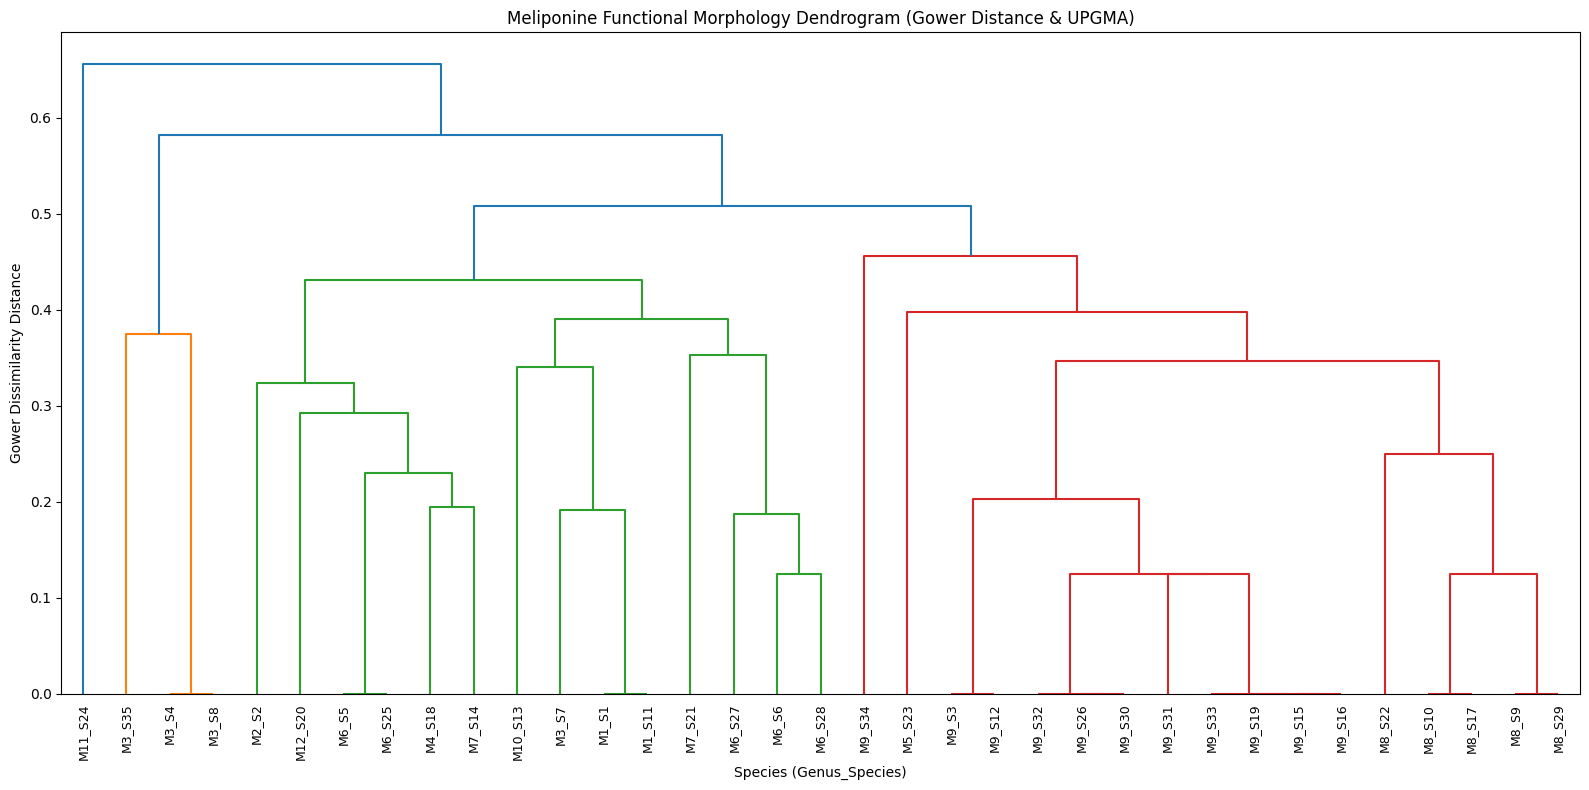

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

-> Saved Dendrogram plot image to: meliponine_genus_dendrogram.png


In [ ]:
# 1. Load and clean your active data
matrix_l, matrix_q, matrix_e = load_and_clean_data()

# 2. Compute the Gower distance matrix
gower_df = compute_functional_gower(matrix_q)

# 3. Call your upgraded function (now passing matrix_q as well)
export_similarity_and_plot_dendrogram(matrix_q, gower_df)

### Step 2 & 3: Community Weighted Means (CWM) & Environmental Correlation Mapping
This block runs the continuous functional ordination (PCoA), weights the species traits by location abundances (Matrix L) to get site-level traits (CWM), and correlates them with abiotic factors (Matrix E) to visualize the relationship.

--- Running PCoA on Gower Distance Matrix ---
Species Coordinates Shape: (35, 2) (35 Species projected onto 2 core axes)

--- Calculating Community Weighted Means (CWM) for 12 Sites ---
CWM Matrix calculated successfully. Shape: (12, 2) (12 Locations x 2 Axes)

--- Correlating Abiotic Factors (Matrix E) with Location CWM coordinates ---
Environmental Correlations with Functional Community Axes:


/usr/local/lib/python3.13/dist-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:259: RuntimeWarning: EIGH: since no value for dimensions is specified, PCoA for all dimensions will be computed, which may result in long computation time if the original distance matrix is large.
  warn(
/usr/local/lib/python3.13/dist-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:404: RuntimeWarning: The result contains negative eigenvalues that are large in magnitude, which may suggest result inaccuracy. See Notes for details. The negative-most eigenvalue is -0.21149005545317504 whereas the largest positive one is 1.770702954297171.
  warn(


,CWM_PC1,CWM_PC2
EL,0.253124,0.286691
LATITUDE,0.060110,0.264825
LONGITUDE,0.071337,-0.085296
INDEX_UV,0.092702,0.114884
LX,0.041138,0.557546
T2M,-0.679268,-0.003768
T2MDEW,-0.544328,-0.522750
RH2M,0.124128,-0.525398
Rd,0.022478,-0.540379
Cd,0.129617,0.468106


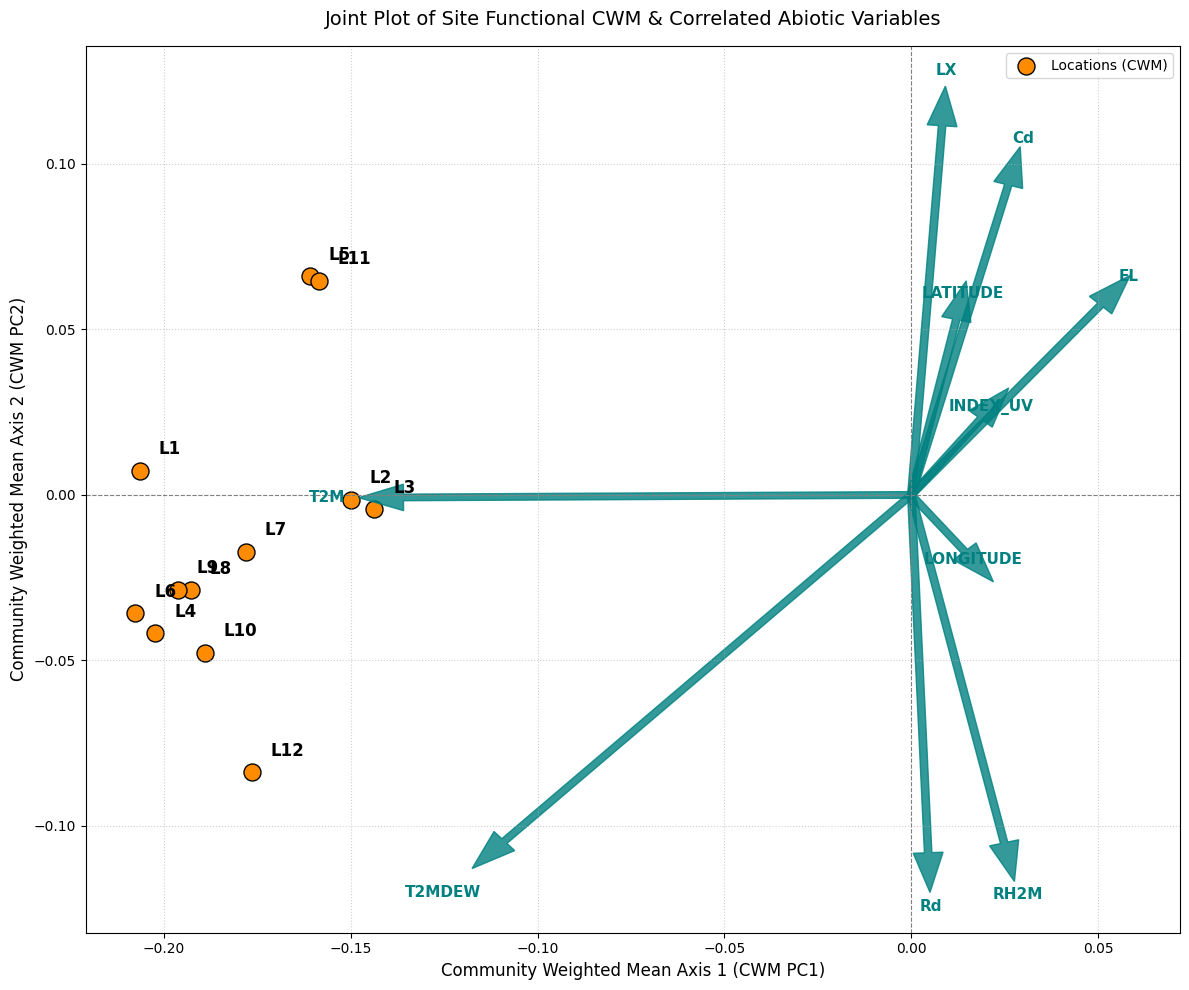

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skbio.stats.ordination import pcoa

# --- 1. Perform Functional Ordination (PCoA) on Gower Distance ---
print("--- Running PCoA on Gower Distance Matrix ---")
# Ensure the diagonal contains exactly zeros to satisfy scikit-bio's hollowness check
gower_matrix_clean = gower_df.values.copy()
np.fill_diagonal(gower_matrix_clean, 0.0)
gower_clean_df = pd.DataFrame(gower_matrix_clean, index=gower_df.index, columns=gower_df.columns)

pcoa_results = pcoa(gower_clean_df)
species_coords = pcoa_results.samples[['PC1', 'PC2']]
print(f"Species Coordinates Shape: {species_coords.shape} (35 Species projected onto 2 core axes)")

# --- 2. Calculate Community Weighted Means (CWM) ---
print("\n--- Calculating Community Weighted Means (CWM) for 12 Sites ---")
# Convert absolute abundances (Matrix L) to relative abundances per site (row-sums = 1)
relative_abundance = matrix_l.div(matrix_l.sum(axis=1), axis=0)

# CWM = Relative Abundance (12 x 35) matrix multiplication with Species Coordinates (35 x 2)
cwm_df = pd.DataFrame(
    np.dot(relative_abundance.values, species_coords.values),
    index=matrix_l.index,
    columns=['CWM_PC1', 'CWM_PC2']
)
print(f"CWM Matrix calculated successfully. Shape: {cwm_df.shape} (12 Locations x 2 Axes)")

# --- 3. Correlate Abiotic Factors (Matrix E) with CWM ---
print("\n--- Correlating Abiotic Factors (Matrix E) with Location CWM coordinates ---")
# Ensure Matrix E indices match Location indices
common_locations = cwm_df.index.intersection(matrix_e.index)
cwm_subset = cwm_df.loc[common_locations]
env_subset = matrix_e.loc[common_locations]

# Calculate Pearson correlation of environmental parameters with our 2 community weighted axes
env_correlations = env_subset.apply(lambda col: cwm_subset.corrwith(col))
print("Environmental Correlations with Functional Community Axes:")
display(env_correlations.T)

# --- 4. Plotting the Joint Space (CWM Sites & Environmental Vectors) ---
plt.figure(figsize=(12, 10))
sns.scatterplot(data=cwm_df, x='CWM_PC1', y='CWM_PC2', s=150, color='darkorange', edgecolor='black', label='Locations (CWM)')

# Add labels to locations
for loc in cwm_df.index:
    plt.text(cwm_df.loc[loc, 'CWM_PC1'] + 0.005, cwm_df.loc[loc, 'CWM_PC2'] + 0.005, loc, fontsize=12, weight='bold')

# Draw environmental vectors scaled to correlation strength
scale_factor = 0.2  # Scaling factor to overlay correlation vectors onto coordinate scale
for env_var in env_correlations.columns:
    dx = env_correlations.loc['CWM_PC1', env_var] * scale_factor
    dy = env_correlations.loc['CWM_PC2', env_var] * scale_factor

    plt.arrow(0, 0, dx, dy, color='teal', width=0.002, head_width=0.008, alpha=0.8)
    plt.text(dx * 1.15, dy * 1.15, env_var, color='teal', fontsize=11, weight='bold', ha='center', va='center')

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title("Joint Plot of Site Functional CWM & Correlated Abiotic Variables", fontsize=14, pad=15)
plt.xlabel("Community Weighted Mean Axis 1 (CWM PC1)", fontsize=12)
plt.ylabel("Community Weighted Mean Axis 2 (CWM PC2)", fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

=== Analysis 1: Bee Colour Abundance vs. Capital Distance (Cd) ===
Black Species (18): ['S1', 'S11', 'S2', 'S7', 'S18']...
Non-Black Species (17): ['S4', 'S8', 'S35', 'S23', 'S6']...

Pearson correlation between Capital Distance (Cd) and % Non-Black Bees: 0.4915


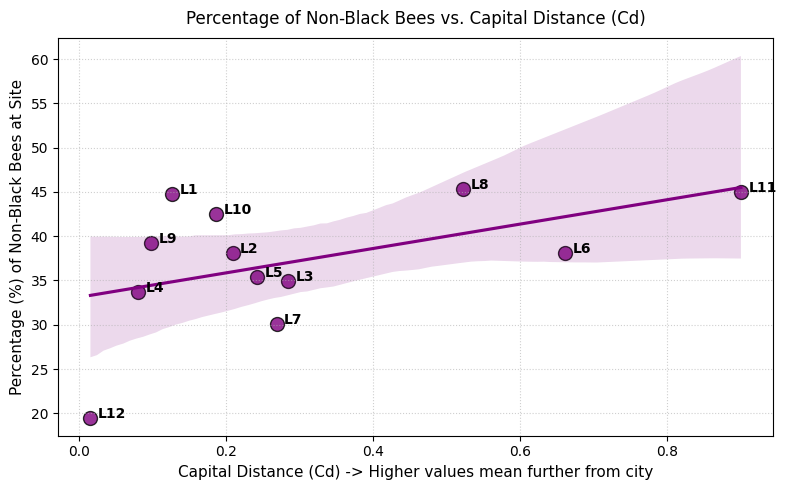

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================================
# ANALYSIS 1: Are non-black bees more common further from the capital (high Cd)?
# =========================================================================

print("=== Analysis 1: Bee Colour Abundance vs. Capital Distance (Cd) ===")

# 1. Identify species colours from Matrix Q
# Note: S24 is 'Unknown' because of a blank cell, let's treat 'black' strictly and others as non-black
black_species = matrix_q[matrix_q['Colour'] == 'black'].index.tolist()
non_black_species = matrix_q[matrix_q['Colour'] != 'black'].index.tolist()

print(f"Black Species ({len(black_species)}): {black_species[:5]}...")
print(f"Non-Black Species ({len(non_black_species)}): {non_black_species[:5]}...")

# 2. Sum abundance per site for Black vs Non-Black bees
site_color_abundance = pd.DataFrame(index=matrix_l.index)
site_color_abundance['Black_Abundance'] = matrix_l[black_species].sum(axis=1)
site_color_abundance['Non_Black_Abundance'] = matrix_l[non_black_species].sum(axis=1)
site_color_abundance['Total_Abundance'] = matrix_l.sum(axis=1)

# Calculate relative abundance (%) per site to avoid site-size bias
site_color_abundance['Pct_Non_Black'] = (site_color_abundance['Non_Black_Abundance'] / site_color_abundance['Total_Abundance']) * 100
site_color_abundance['Cd'] = matrix_e['Cd']

# Calculate correlation
correlation_cd_color = site_color_abundance['Cd'].corr(site_color_abundance['Pct_Non_Black'])
print(f"\nPearson correlation between Capital Distance (Cd) and % Non-Black Bees: {correlation_cd_color:.4f}")

# Plot the relationship
plt.figure(figsize=(8, 5))
sns.regplot(data=site_color_abundance, x='Cd', y='Pct_Non_Black', color='purple', scatter_kws={'s': 100, 'edgecolor': 'black'})
for loc in site_color_abundance.index:
    plt.text(site_color_abundance.loc[loc, 'Cd'] + 0.01, site_color_abundance.loc[loc, 'Pct_Non_Black'], loc, fontsize=10, weight='bold')
plt.title("Percentage of Non-Black Bees vs. Capital Distance (Cd)", fontsize=12, pad=10)
plt.xlabel("Capital Distance (Cd) -> Higher values mean further from city", fontsize=11)
plt.ylabel("Percentage (%) of Non-Black Bees at Site", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


=== Analysis 2: Mapping Categorical Traits to Species PCoA Space ===


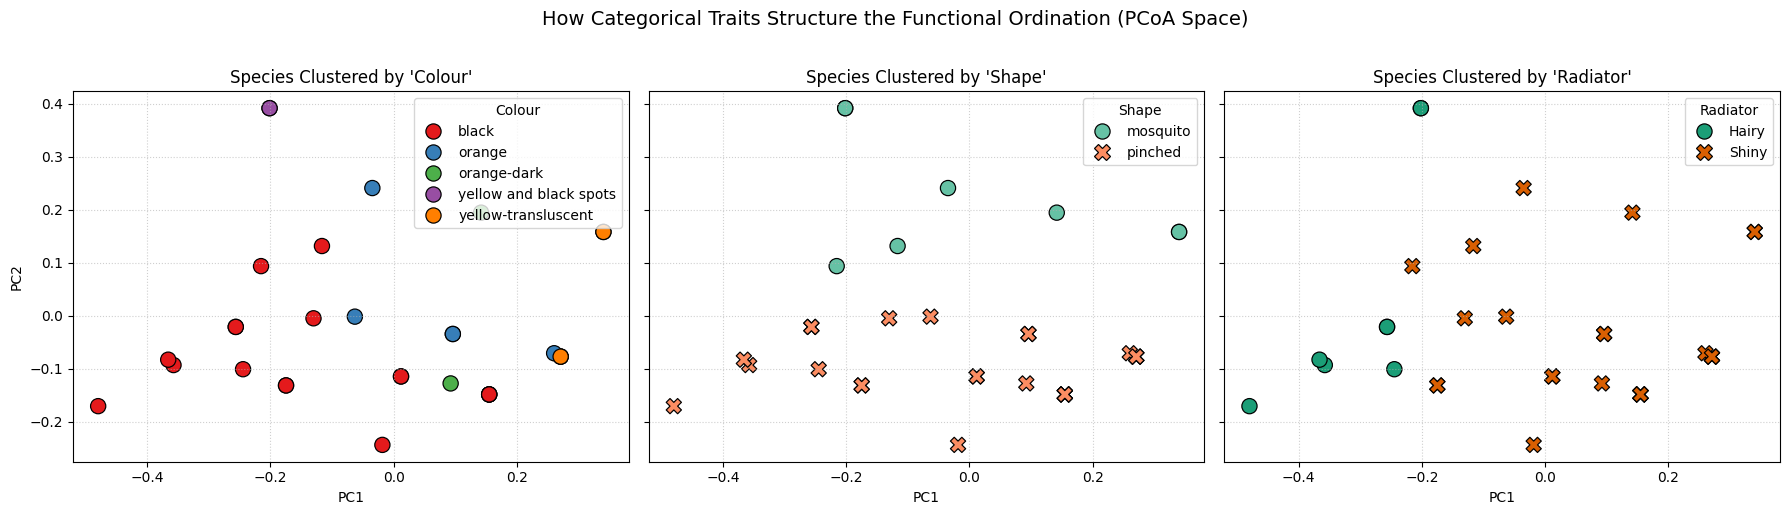

In [ ]:
# =========================================================================
# ANALYSIS 2: Visualizing Traits (Shape, Colour, Radiator) in PCoA Space
# =========================================================================

print("\n=== Analysis 2: Mapping Categorical Traits to Species PCoA Space ===")

# Align species coordinates with traits
species_coords_traits = species_coords.copy()
species_coords_traits['Colour'] = matrix_q['Colour'].values
species_coords_traits['Shape'] = matrix_q['Shape'].values
species_coords_traits['Radiator'] = matrix_q['Radiator'].values

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

# Plot 1: Colour
sns.scatterplot(ax=axes[0], data=species_coords_traits, x='PC1', y='PC2', hue='Colour', s=120, edgecolor='black', palette='Set1')
axes[0].set_title("Species Clustered by 'Colour'", fontsize=12)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Shape
sns.scatterplot(ax=axes[1], data=species_coords_traits, x='PC1', y='PC2', hue='Shape', style='Shape', s=120, edgecolor='black', palette='Set2')
axes[1].set_title("Species Clustered by 'Shape'", fontsize=12)
axes[1].grid(True, linestyle=':', alpha=0.6)

# Plot 3: Radiator
sns.scatterplot(ax=axes[2], data=species_coords_traits, x='PC1', y='PC2', hue='Radiator', style='Radiator', s=120, edgecolor='black', palette='Dark2')
axes[2].set_title("Species Clustered by 'Radiator'", fontsize=12)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.suptitle("How Categorical Traits Structure the Functional Ordination (PCoA Space)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Pearson correlation between Capital Distance (Cd) and % Black Bees: -0.4915


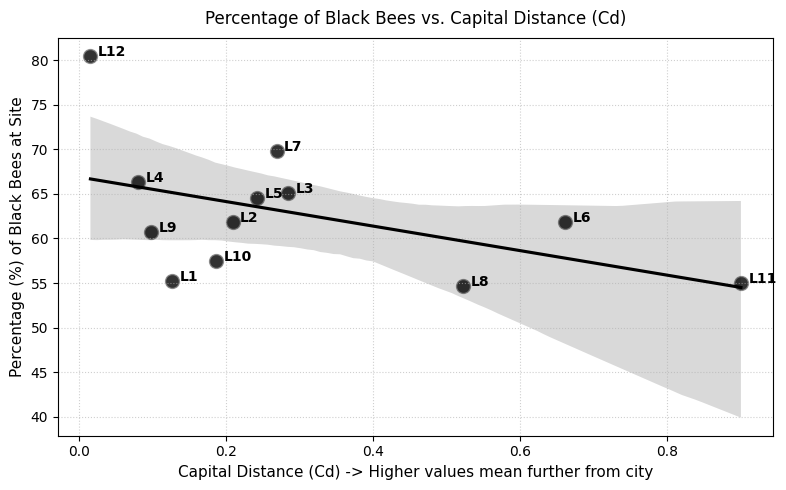

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================================
# NEW ANALYSIS: Percentage of Black Bees vs. Capital Distance (Cd)
# =========================================================================

# 1. Sum up absolute abundances per site for black species
black_species_list = matrix_q[matrix_q['Colour'] == 'black'].index.tolist()
site_color_abundance['Black_Abundance'] = matrix_l[black_species_list].sum(axis=1)
site_color_abundance['Total_Abundance'] = matrix_l.sum(axis=1)

# 2. Calculate relative percentage of black bees per site
site_color_abundance['Pct_Black_Bees'] = (site_color_abundance['Black_Abundance'] / site_color_abundance['Total_Abundance']) * 100
site_color_abundance['Cd'] = matrix_e['Cd']

# 3. Calculate correlation
correlation_cd_black = site_color_abundance['Cd'].corr(site_color_abundance['Pct_Black_Bees'])
print(f"Pearson correlation between Capital Distance (Cd) and % Black Bees: {correlation_cd_black:.4f}")

# 4. Plot the trend
plt.figure(figsize=(8, 5))
sns.regplot(data=site_color_abundance, x='Cd', y='Pct_Black_Bees', color='black', scatter_kws={'s': 100, 'edgecolor': 'gray'})
for loc in site_color_abundance.index:
    plt.text(site_color_abundance.loc[loc, 'Cd'] + 0.01, site_color_abundance.loc[loc, 'Pct_Black_Bees'], loc, fontsize=10, weight='bold')

plt.title("Percentage of Black Bees vs. Capital Distance (Cd)", fontsize=12, pad=10)
plt.xlabel("Capital Distance (Cd) -> Higher values mean further from city", fontsize=11)
plt.ylabel("Percentage (%) of Black Bees at Site", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. Identify species categories
mosquito_black = matrix_q[(matrix_q['Shape'] == 'mosquito') & (matrix_q['Colour'] == 'black')].index.tolist()
mosquito_non_black = matrix_q[(matrix_q['Shape'] == 'mosquito') & (matrix_q['Colour'] != 'black')].index.tolist()

print(f"Mosquito-shaped Black species: {mosquito_black}")
print(f"Mosquito-shaped Non-black species: {mosquito_non_black}")

# 2. Select sites closest to the city (e.g., lower half of Cd values, or top closest sites)
# Let's sort locations by Capital Distance (Cd) ascending
closest_sites = matrix_e.sort_values(by='Cd').index[:3].tolist() # Top 3 closest to the city
print(f"\nSites closest to the city (lowest Cd): {closest_sites}")
for site in closest_sites:
    print(f"  Site {site}: Cd = {matrix_e.loc[site, 'Cd']:.4f}")

# 3. Sum up abundances at these close sites
print("\n--- Abundances at Sites Near the City ---")
for site in closest_sites:
    ab_black = matrix_l.loc[site, mosquito_black].sum()
    ab_non_black = matrix_l.loc[site, mosquito_non_black].sum()
    print(f"Location {site}: Mosquito-Black = {ab_black} individuals | Mosquito-Non-Black = {ab_non_black} individuals")

# Total overall nearby abundance comparison
total_black_near = matrix_l.loc[closest_sites, mosquito_black].sum().sum()
total_non_black_near = matrix_l.loc[closest_sites, mosquito_non_black].sum().sum()

print(f"\nOverall Total in the 3 Closest Sites:")
print(f"- Mosquito-shaped Black Bees: {total_black_near}")
print(f"- Mosquito-shaped Non-black Bees: {total_non_black_near}")

Mosquito-shaped Black species: ['S27', 'S21']
Mosquito-shaped Non-black species: ['S4', 'S8', 'S28', 'S22', 'S3', 'S12']

Sites closest to the city (lowest Cd): ['L12', 'L4', 'L9']
  Site L12: Cd = 0.0160
  Site L4: Cd = 0.0807
  Site L9: Cd = 0.0989

--- Abundances at Sites Near the City ---
Location L12: Mosquito-Black = 0 individuals | Mosquito-Non-Black = 7 individuals
Location L4: Mosquito-Black = 1 individuals | Mosquito-Non-Black = 31 individuals
Location L9: Mosquito-Black = 1 individuals | Mosquito-Non-Black = 55 individuals

Overall Total in the 3 Closest Sites:
- Mosquito-shaped Black Bees: 2
- Mosquito-shaped Non-black Bees: 93


In [ ]:
import pandas as pd

# 1. Identify species categories
pinched_black = matrix_q[(matrix_q['Shape'] == 'pinched') & (matrix_q['Colour'] == 'black')].index.tolist()
pinched_non_black = matrix_q[(matrix_q['Shape'] == 'pinched') & (matrix_q['Colour'] != 'black')].index.tolist()

print(f"Pinched-shaped Black species: {pinched_black}")
print(f"Pinched-shaped Non-black species: {pinched_non_black}")

# 2. Select sites closest to the city
closest_sites = ['L12', 'L4', 'L9']

# 3. Sum up abundances at these close sites
print("\n--- Abundances at Sites Near the City (Pinched Abdomen) ---")
for site in closest_sites:
    ab_black = matrix_l.loc[site, pinched_black].sum()
    ab_non_black = matrix_l.loc[site, pinched_non_black].sum()
    print(f"Location {site}: Pinched-Black = {ab_black} | Pinched-Non-Black = {ab_non_black}")

# Total overall nearby abundance comparison
total_black_near = matrix_l.loc[closest_sites, pinched_black].sum().sum()
total_non_black_near = matrix_l.loc[closest_sites, pinched_non_black].sum().sum()

print(f"\nOverall Total in the 3 Closest Sites:")
print(f"- Pinched-shaped Black Bees: {total_black_near}")
print(f"- Pinched-shaped Non-black Bees: {total_non_black_near}")

Pinched-shaped Black species: ['S1', 'S11', 'S2', 'S7', 'S18', 'S5', 'S25', 'S14', 'S10', 'S17', 'S15', 'S16', 'S19', 'S33', 'S13', 'S20']
Pinched-shaped Non-black species: ['S23', 'S6', 'S9', 'S29', 'S26', 'S30', 'S31', 'S32']

--- Abundances at Sites Near the City (Pinched Abdomen) ---
Location L12: Pinched-Black = 33 | Pinched-Non-Black = 1
Location L4: Pinched-Black = 66 | Pinched-Non-Black = 3
Location L9: Pinched-Black = 98 | Pinched-Non-Black = 8

Overall Total in the 3 Closest Sites:
- Pinched-shaped Black Bees: 197
- Pinched-shaped Non-black Bees: 12


In [ ]:
import pandas as pd

# 1. Select the 3 sites furthest from the city (highest Cd)
furthest_sites = matrix_e.sort_values(by='Cd', ascending=False).index[:3].tolist()
print(f"Sites furthest from the city (highest Cd): {furthest_sites}")
for site in furthest_sites:
    print(f"  Site {site}: Cd = {matrix_e.loc[site, 'Cd']:.4f}")

# 2. Extract species groups for shapes and colors
mosquito_black = matrix_q[(matrix_q['Shape'] == 'mosquito') & (matrix_q['Colour'] == 'black')].index.tolist()
mosquito_non_black = matrix_q[(matrix_q['Shape'] == 'mosquito') & (matrix_q['Colour'] != 'black')].index.tolist()

pinched_black = matrix_q[(matrix_q['Shape'] == 'pinched') & (matrix_q['Colour'] == 'black')].index.tolist()
pinched_non_black = matrix_q[(matrix_q['Shape'] == 'pinched') & (matrix_q['Colour'] != 'black')].index.tolist()

# 3. Compute and print abundances per site
print("\n--- Detailed Abundances at Remote Sites ---")
for site in furthest_sites:
    m_black = matrix_l.loc[site, mosquito_black].sum()
    m_non_black = matrix_l.loc[site, mosquito_non_black].sum()
    p_black = matrix_l.loc[site, pinched_black].sum()
    p_non_black = matrix_l.loc[site, pinched_non_black].sum()

    print(f"Location {site}:")
    print(f"  * Mosquito-shaped -> Black: {m_black} | Non-black: {m_non_black}")
    print(f"  * Pinched-abdomen -> Black: {p_black} | Non-black: {p_non_black}")

# 4. Overall Totals
print("\nOverall Totals across the 3 Furthest Sites:")
print(f"- Mosquito Black: {matrix_l.loc[furthest_sites, mosquito_black].sum().sum()}")
print(f"- Mosquito Non-Black: {matrix_l.loc[furthest_sites, mosquito_non_black].sum().sum()}")
print(f"- Pinched Black: {matrix_l.loc[furthest_sites, pinched_black].sum().sum()}")
print(f"- Pinched Non-Black: {matrix_l.loc[furthest_sites, pinched_non_black].sum().sum()}")

Sites furthest from the city (highest Cd): ['L11', 'L6', 'L8']
  Site L11: Cd = 0.9000
  Site L6: Cd = 0.6609
  Site L8: Cd = 0.5224

--- Detailed Abundances at Remote Sites ---
Location L11:
  * Mosquito-shaped -> Black: 1 | Non-black: 27
  * Pinched-abdomen -> Black: 48 | Non-black: 13
Location L6:
  * Mosquito-shaped -> Black: 1 | Non-black: 45
  * Pinched-abdomen -> Black: 98 | Non-black: 14
Location L8:
  * Mosquito-shaped -> Black: 3 | Non-black: 46
  * Pinched-abdomen -> Black: 73 | Non-black: 16

Overall Totals across the 3 Furthest Sites:
- Mosquito Black: 5
- Mosquito Non-Black: 118
- Pinched Black: 219
- Pinched Non-Black: 43
